In [42]:
 import sys
 !{sys.executable} -m pip install --user -qq scikit-learn

In [23]:
!pip install -qq pandas numpy matplotlib seaborn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline


In [24]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
score_data = pd.read_csv(url)
score_data.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [25]:
len(score_data)

5000

In [26]:
score_data.columns = score_data.columns.str.lower().str.replace(' ', '_')

In [27]:
score_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [28]:
score_data.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [29]:
score_data.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [30]:
score_data.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [31]:
df = score_data.copy()
categorical_cols = df.select_dtypes(include=['object', 'string']).columns
df[categorical_cols] = df[categorical_cols].fillna('NA')

numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
df[numerical_cols] = df[numerical_cols].fillna(0.0)


In [32]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [33]:
df['industry'].mode()

0    technology
Name: industry, dtype: str

In [34]:
# correlation matrix
numerical_cols = [
    'annual_income', 
    'number_of_courses_viewed', 
    'interaction_count', 
    'lead_score', 
    'converted'
]
corr_matrix = df[numerical_cols].corr()
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.expand_frame_repr', False)
print(corr_matrix)

                          annual_income  number_of_courses_viewed  interaction_count  lead_score  converted
annual_income                  1.000000                  0.161300           0.122842    0.229496   0.189652
number_of_courses_viewed       0.161300                  1.000000           0.721609    0.757204   0.395038
interaction_count              0.122842                  0.721609           1.000000    0.915746   0.448624
lead_score                     0.229496                  0.757204           0.915746    1.000000   0.483246
converted                      0.189652                  0.395038           0.448624    0.483246   1.000000


In [35]:
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
strongest_pairs = corr_matrix.where(mask).unstack().dropna()
top_correlation = strongest_pairs.abs().sort_values(ascending=False).head(1)
print("The two features with the biggest correlation:")
top_pair_name = top_correlation.index[0]
actual_value = strongest_pairs[top_pair_name]
print(f"Features: {top_pair_name[0]} and {top_pair_name[1]}")
print(f"Correlation: {actual_value:.2f}")

The two features with the biggest correlation:
Features: lead_score and interaction_count
Correlation: 0.92


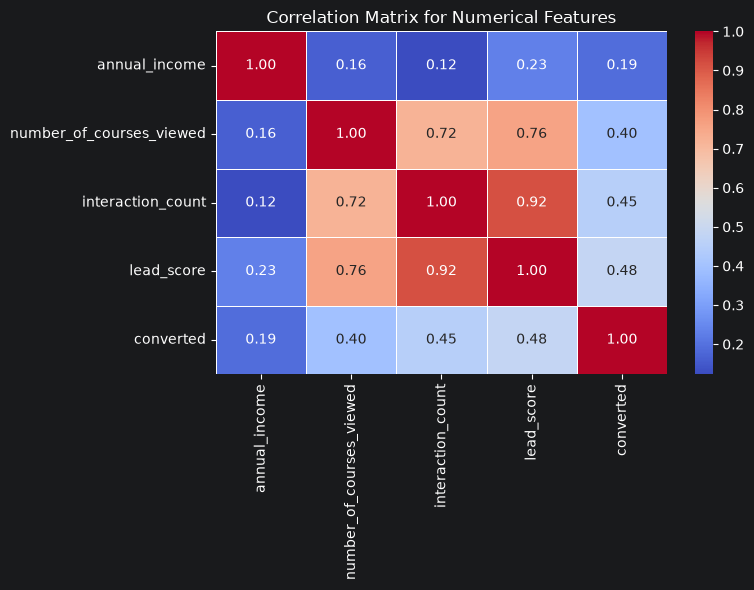

In [36]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix for Numerical Features')
plt.tight_layout()
plt.show()

In [37]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])
df_test = df_test.drop(columns=['converted'])

categorical_vars = ['lead_source', 'industry', 'employment_status', 'location']

for col in categorical_vars:
    score = mutual_info_score(df_train[col], y_train)
    print(f"{col}: {round(score, 2)}")

lead_source: 0.03
industry: 0.0
employment_status: 0.02
location: 0.0


In [38]:
# lead_source has the biggest mutual information score at 0.03

In [39]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_val)
accuracy = accuracy_score(y_val, y_pred)
print('Accuracy on the validation dataset:')
print(round(accuracy, 2))

Accuracy on the validation dataset:
0.65


In [40]:
features = list(df_train.columns)
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
original_accuracy = accuracy_score(y_val, y_pred)
print(f"Original Accuracy for all features: {original_accuracy}\n")
scores_diff = {}

for c in features:
    subset_features = [f for f in features if f != c]
    sub_train_dicts = df_train[subset_features].to_dict(orient='records')
    sub_val_dicts = df_val[subset_features].to_dict(orient='records')
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(sub_train_dicts)
    X_val_sub = dv_sub.transform(sub_val_dicts)
    sub_model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)
    sub_model.fit(X_train_sub, y_train)
    
    sub_y_pred = sub_model.predict(X_val_sub)
    acc = accuracy_score(y_val, sub_y_pred)
    difference = original_accuracy - acc
    scores_diff[c] = difference
    print(f"Without {c:25} -> Accuracy: {acc:.5f} | Difference: {difference:.5f}")

least_useful = min(scores_diff, key=scores_diff.get)
print(f"\nLeast useful feature (smallest drop/largest increase in accuracy when removed): {least_useful}")

options = ['lead_source', 'number_of_courses_viewed', 'interaction_count']
smallest_feature = min(options, key=lambda f: scores_diff[f])
print(f"\nFeature with the smallest difference: {smallest_feature}")
print(f"Difference value: {scores_diff[smallest_feature]}")

Original Accuracy for all features: 0.645

Without lead_source               -> Accuracy: 0.64200 | Difference: 0.00300
Without industry                  -> Accuracy: 0.64500 | Difference: 0.00000
Without employment_status         -> Accuracy: 0.64500 | Difference: 0.00000
Without location                  -> Accuracy: 0.64500 | Difference: 0.00000
Without annual_income             -> Accuracy: 0.72400 | Difference: -0.07900
Without number_of_courses_viewed  -> Accuracy: 0.64300 | Difference: 0.00200
Without interaction_count         -> Accuracy: 0.60100 | Difference: 0.04400
Without lead_score                -> Accuracy: 0.64400 | Difference: 0.00100

Least useful feature (smallest drop/largest increase in accuracy when removed): annual_income

Feature with the smallest difference: number_of_courses_viewed
Difference value: 0.0020000000000000018


In [41]:
features = list(df_train.columns)
train_dicts = df_train[features].to_dict(orient='records')
val_dicts = df_val[features].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

C_values = [0.000001, 0.00001, 0.0001, 0.001]
results = {}

for c in C_values:
    model = LogisticRegression(solver='liblinear', C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    rounded_acc = round(acc, 3)
    results[c] = rounded_acc
    print(f"C = {c} -> Accuracy: {rounded_acc}")

best_c = max(results, key=lambda x: (results[x], -x)) 
best_accuracy = max(results.values())
tied_cs = [c for c, acc in results.items() if acc == best_accuracy]
print(f"\nBest accuracy: {best_accuracy}")
print(f"Best C values([0.000001, 0.00001, 0.0001, 0.001]) with this accuracy is : {tied_cs}")
print(f"Selected C (smallest among ties): {min(tied_cs)}")

C = 1e-06 -> Accuracy: 0.598
C = 1e-05 -> Accuracy: 0.598
C = 0.0001 -> Accuracy: 0.613
C = 0.001 -> Accuracy: 0.645

Best accuracy: 0.645
Best C values([0.000001, 0.00001, 0.0001, 0.001]) with this accuracy is : [0.001]
Selected C (smallest among ties): 0.001
